# Masked-sky rotation reconstruction: with and without miscalibration
Single-frequency comparison at **nside=512**, **lmax_ivf=lmax_qlm=1024** using the existing isotropic filter.

Read **field 2 (zero-based, the third column)** of `binary_GAL_mask_N1024.fits`. Downgrade the mask from nside 1024 to 512 with `hp.ud_grade`; fractional edge weights are retained. The observation is
$$m_\nu^{\rm obs}=M\,[B_\nu\,R(\alpha_\nu)R(a(\hat n))m_{\rm CMB}+n_\nu].$$
The mask acts at the very last step, including on noise. Compare `alpha=None` with `alpha=0.2` **degrees**, retaining the same spatial rotation amplitude `Acb` and realization seeds. “Without alpha” here means no constant instrumental miscalibration, not removal of the anisotropic field.

**Interpretation:** the filter, full-sky QE response, and existing noise estimate are unchanged. Plotted reconstructed spectra are masked-sky diagnostics: no mean-field subtraction, mode-coupling correction, empirical response calibration, or sky-fraction rescaling is applied. The analytic full-sky input is a reference, not an exact prediction for the masked estimator.

In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path
import time

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
from sim import CMBobs
from recon import AlphaRecon

plt.rcParams.update({'figure.dpi':120, 'axes.grid':True, 'grid.alpha':0.2})
nside = 512
lmax_ivf = 1024
lmax_qlm = 1024
lmin_ivf = 20
nlevp = 2.0       # uK-arcmin
fwhm = 8.0        # arcmin
Acb = 1e-7       # shared anisotropic rotation, rad²
alpha_deg = 0.05   # constant channel miscalibration, degrees
sim_indices = tuple(range(4))
bin_width = 32
mask_path = Path('binary_GAL_mask_N1024.fits')
mask_field = 2
assert mask_path.exists(), f'Place the supplied mask at {mask_path.resolve()}'
assert len(sim_indices) >= 2

native_mask = hp.read_map(str(mask_path), field=mask_field, dtype=float)
assert hp.npix2nside(native_mask.size) == 1024
mask = hp.ud_grade(native_mask, nside, order_in='RING', order_out='RING')
del native_mask
kwargs = dict(nside=nside, nlevp=nlevp, fwhm=fwhm, Acb=Acb, mask=mask)
obs_none = CMBobs(alpha=None, **kwargs)
obs_alpha = CMBobs(alpha=alpha_deg, **kwargs)
np.testing.assert_array_equal(obs_none.mask, mask)
np.testing.assert_array_equal(obs_alpha.mask, mask)
config = dict(nside=nside,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm,lmin_ivf=lmin_ivf,
              nlevp=nlevp,fwhm=fwhm,Acb=Acb,alpha_deg=alpha_deg,
              mask_sha256=hashlib.sha256(mask.tobytes()).hexdigest())
tag = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:16]
root = Path('data')/'masked_reconstruction'/tag
rec_kwargs = dict(lmin_ivf=lmin_ivf,lmax_ivf=lmax_ivf,lmax_qlm=lmax_qlm)
rec_none = AlphaRecon(obs_none,root/'no_alpha',**rec_kwargs)
rec_alpha = AlphaRecon(obs_alpha,root/'with_alpha',**rec_kwargs)
# Verify that only the simulated maps differ; the current filters are identical.
for name in ['get_ftl','get_fel','get_fbl']:
    np.testing.assert_array_equal(getattr(rec_none.ivfs,name)(),getattr(rec_alpha.ivfs,name)())
f1,f2,f4 = [np.mean(mask**power) for power in [1,2,4]]
print(f'Mask field {mask_field}: mean(M)={f1:.6f}, mean(M²)={f2:.6f}, mean(M⁴)={f4:.6f}')
print(f'Fractional boundary pixels: {np.count_nonzero((mask>0)&(mask<1))}')
print('Both filters unchanged; no sky-fraction normalization applied.')
print('Cache:',root)

Caching sky fractions...
Caching sky fractions...
Mask field 2: mean(M)=0.700125, mean(M²)=0.699849, mean(M⁴)=0.699628
Fractional boundary pixels: 4279
Both filters unchanged; no sky-fraction normalization applied.
Cache: data/masked_reconstruction/379019e4ea85f497


/Users/antoidicherianlonappan/Software/plancklens/plancklens/utils.py:124: RuntimeWarning: overflow encountered in cast
  return hashlib.sha1(np.copy(cl.astype(dtype), order='C')).hexdigest()


## Matched reconstruction ensemble
Each pair uses identical CMB, spatial rotation, and noise seeds. Only the constant miscalibration differs. The truth alms below describe the common full-sky anisotropic field; cross-spectra measure how the masked reconstruction responds to it.

The existing `AlphaRecon.noise_spectrum` is a full-sky semi-analytical estimate applied to masked data. Its subtraction is displayed as a diagnostic only; it is not a calibrated cut-sky bias subtraction.

In [2]:
L=np.arange(lmax_qlm+1)
cl_aa=obs_none.cl_aa()[:lmax_qlm+1]
ells,ms=hp.Alm.getlm(lmax_qlm)
selection=hp.Alm.getidx(obs_none.lmax,ells,ms)
results={case:{key:[] for key in ['auto','cross','n0']} for case in ['no_alpha','with_alpha']}
input_cls=[]
start=time.perf_counter()
for idx in sim_indices:
    truth=obs_none.alpha_alm(idx)[selection]
    input_cls.append(hp.alm2cl(truth))
    for case,rec in [('no_alpha',rec_none),('with_alpha',rec_alpha)]:
        estimate=rec.reconstruct(idx)
        results[case]['auto'].append(hp.alm2cl(estimate))
        results[case]['cross'].append(hp.alm2cl(estimate,truth))
        results[case]['n0'].append(rec.noise_spectrum(idx))
        print(f'{case}, idx={idx}, elapsed={time.perf_counter()-start:.1f} s',flush=True)
results={case:{key:np.asarray(value) for key,value in values.items()}
         for case,values in results.items()}
input_cls=np.asarray(input_cls)
assert all(np.isfinite(value).all() for values in results.values() for value in values.values())
np.savez(root/'comparison_cls.npz',ell=L,theory=cl_aa,input=input_cls,
         indices=np.array(sim_indices),**{f'{case}_{key}':value
             for case,values in results.items() for key,value in values.items()})
print('Saved raw spectra:',root/'comparison_cls.npz')

no_alpha, idx=0, elapsed=3.8 s
with_alpha, idx=0, elapsed=7.6 s
no_alpha, idx=1, elapsed=11.3 s
with_alpha, idx=1, elapsed=14.9 s
no_alpha, idx=2, elapsed=18.5 s
with_alpha, idx=2, elapsed=22.1 s
no_alpha, idx=3, elapsed=26.0 s
with_alpha, idx=3, elapsed=29.6 s
Saved raw spectra: data/masked_reconstruction/379019e4ea85f497/comparison_cls.npz


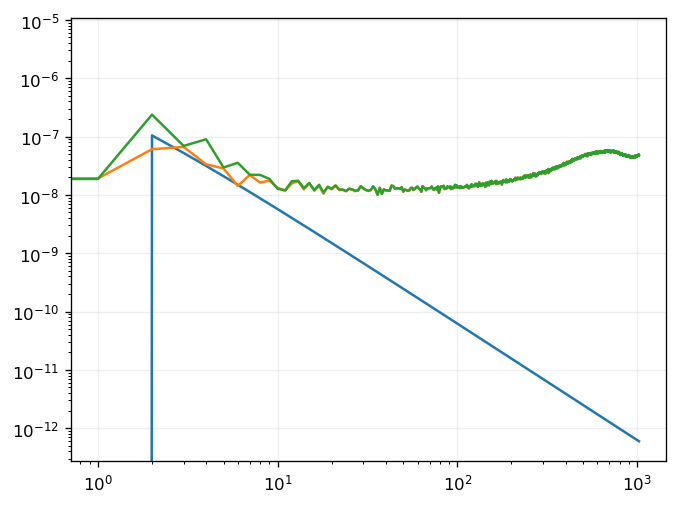

In [3]:
plt.loglog(cl_aa)
plt.loglog(results['no_alpha']['auto'].mean(axis=0), label='No alpha')
plt.loglog(results['with_alpha']['auto'].mean(axis=0), label='With alpha')
plt.show()
